# 10 — M3-RVA Evaluation and Comparison
## Resume V2 with explicit accounting for image-only technical exclusions

**This is the continuation repair, not another training run or a new 400-episode restart.**
It reads the unchanged V2 evaluator and validates/reuses existing scored episodes. It installs
only `src/m3_rva_completion.py`, a companion execution-and-analysis runner.

A model-free reset diagnostic reproduced wrist-camera differences. This notebook **does not
repair renderer determinism**, enlarge image tolerances, replace policy inputs, or declare a
rejected pair valid. It changes only what happens after an image-only pairing rejection:
record the attempt as **unscored**, do not retry it, and continue other scheduled slots.

| Case | Treatment |
|---|---|
| Compatible existing V2 episode and capture | Validate and reuse without rerunning |
| Known saved image-only rejection | Recompute from saved arrays; retain a terminal unscored record; no new reset |
| New image-only rejection with matching state/identity | Save unscored evidence before any learned action; continue |
| State, schema, corrupted-file, invalid-action, or unrelated error | Still stop; not converted into task failure or silently ignored |
| `TIMEOUT` after a valid rollout | Ordinary unsuccessful manipulation outcome |

**Unscored is not `success=False`.** Paired performance uses only complete valid model pairs.
A scored baseline-only row is retained but is excluded from the paired-rate comparison.
The report includes coverage and conservative bounds for the unknown scheduled outcomes.
Conditions with incomplete coverage have no bootstrap or p-value claimed in this amendment;
fully observed conditions retain the original estimator. All findings remain exploratory.

**Last reviewed progress:** the supplied log had 367 completed episode entries and one rejected
reset. The actual local files are checked at runtime. With those files intact, this should leave
32 slots requiring policy rollouts, not 400. This is a planning count, not a fabricated final result.

### Run
Save/backup the currently executed N10 before replacing it. Use **Python (`vla-libero`)**, keep
N09 and other M3 jobs idle, restart this notebook's kernel and choose **Run All**.
The defaults below continue seed 42. Do not run the old V2 notebook simultaneously or retry
rejected resets to obtain a more favorable observation.

New analysis and terminal records go to `results/metrics/m3_rva_evaluation/v2_completion_v1/`.
New valid episodes/captures append under `v2/` with an explicit execution-amendment tag.
**Every pre-existing V2 file is inventoried and must remain byte-identical.** Original V2
protocols and summaries are not rewritten. N09, model weights, processors and LeRobot source
are unchanged.


In [2]:
RUN_M3_CLOSED_LOOP = True
EVALUATION_SEEDS = [42, 123, 2026]  # Use other planned seeds only after N09 completes them; never select by score.


## 1. Locate the existing project
This continuation expects the reviewed V2 evaluator and saved V2 workspace already to exist.
It does not silently create a new protocol, switch Python environments, or install dependencies.


In [3]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import os
import signal
import subprocess
import sys
from collections import deque
import pandas as pd
from IPython.display import display, Image

start = Path.cwd().resolve()
candidates = [start, *start.parents]
REPO_ROOT = next((p for p in candidates if (p / "notebooks").is_dir() and (p / "src").is_dir()), None)
if REPO_ROOT is None:
    raise RuntimeError("Open this notebook in the existing deep-learning-vla-robustness project.")
if Path(sys.prefix).name != "vla-libero":
    raise RuntimeError(f"Select Python (vla-libero), not {sys.executable}. Do not install into system Python.")
V2_PATH = REPO_ROOT / "src/m3_rva_evaluation.py"
RUNNER_PATH = REPO_ROOT / "src/m3_rva_completion.py"
OUTPUT_DIR = REPO_ROOT / "results/metrics/m3_rva_evaluation/v2_completion_v1"
FIGURES_DIR = REPO_ROOT / "results/figures/m3_rva_evaluation/v2_completion_v1"
BASE_SHA256 = "60e5757f7c08c5207268ea3631e9e5f22949877a4f68de82c9148d72c721e9ef"
print("Project:", REPO_ROOT)
print("Python:", sys.executable)
print("Original evaluator (read only):", V2_PATH)
print("New completion report directory:", OUTPUT_DIR)


Project: /home/leeming/projects/deep-learning-vla-robustness
Python: /home/leeming/miniforge3/envs/vla-libero/bin/python
Original evaluator (read only): /home/leeming/projects/deep-learning-vla-robustness/src/m3_rva_evaluation.py
New completion report directory: /home/leeming/projects/deep-learning-vla-robustness/results/metrics/m3_rva_evaluation/v2_completion_v1


## 2. Install the visible completion runner
The complete companion source below is part of this notebook. It imports the exact original
V2 module **without running its `main()`**, reuses its reset/rollout/threshold logic, and adds
specific image-only exception accounting. There is no broad `except: continue` in the rollout.
The original evaluator file is not replaced; only this new companion is installed.


In [4]:
COMPLETION_SOURCE = r'''"""N10 V2 completion amendment: preserve scored evidence; never score image-only rejects.

This is a completion/error-accounting repair, not a renderer determinism fix.
The original V2 evaluator, comparison thresholds, reset/rollout helpers, trained
weights and processor files are not edited. Known image-only rejects are terminal
unscored attempts, not retried. Other exceptions remain fatal. Existing compatible
V2 episodes are revalidated and reused; only missing, nonterminal slots are run.
New analysis/ledgers are separate from original V2 summaries and protocols.
"""
from __future__ import annotations

import argparse
from contextlib import contextmanager
from datetime import datetime, timezone
import hashlib
import importlib.util
import json
import math
import os
from pathlib import Path
import sys
import traceback
from typing import Any

import numpy as np
import pandas as pd

BASE_SHA = '60e5757f7c08c5207268ea3631e9e5f22949877a4f68de82c9148d72c721e9ef'
AMENDMENT = 'm3_v2_completion_v1'
OUTPUT_REL = 'results/metrics/m3_rva_evaluation/v2_completion_v1'
IDENTITY = ('task_id', 'condition_id', 'replica', 'initial_state_index',
            'initial_state_vector_sha256', 'evaluation_protocol_sha256')
PAIR_KEYS = ['model_seed', 'condition_id', 'suite_task_id', 'replica']
PAIR_MATCH = ['episode_seed', 'policy_rng_seed', 'max_steps', 'instruction',
              'initial_state_index', 'initial_state_vector_sha256', 'nonimage_observation_sha256']


def require(condition: Any, message: str) -> None:
    if not bool(condition):
        raise RuntimeError(message)


def sha(path: Path) -> str:
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(8 * 1024**2), b''):
            h.update(block)
    return h.hexdigest()


def clean(value: Any) -> Any:
    if isinstance(value, dict):
        return {str(k): clean(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [clean(v) for v in value]
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.generic):
        return clean(value.item())
    if isinstance(value, np.ndarray):
        return clean(value.tolist())
    if isinstance(value, float) and not math.isfinite(value):
        return None
    return value


def read(path: Path) -> dict:
    return json.loads(Path(path).read_text(encoding='utf-8'))


def atomic_json(path: Path, value: dict, *, immutable: bool = False) -> None:
    value = clean(value)
    path = Path(path)
    if immutable and path.exists():
        require(read(path) == value, f'Immutable record differs: {path}')
        return
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + '.tmp')
    with tmp.open('w', encoding='utf-8') as f:
        json.dump(value, f, indent=2, allow_nan=False)
        f.flush()
        os.fsync(f.fileno())
    tmp.replace(path)


def utc() -> str:
    return datetime.now(timezone.utc).isoformat()


def load_base(root: Path):
    path = root / 'src/m3_rva_evaluation.py'
    require(path.is_file() and sha(path) == BASE_SHA,
            'The original V2 evaluator is missing or locally changed. Preserve it for review; do not replace its hash.')
    spec = importlib.util.spec_from_file_location('_unchanged_n10_v2', path)
    require(spec is not None and spec.loader is not None, 'Cannot import the unchanged V2 evaluator.')
    module = importlib.util.module_from_spec(spec)
    sys.modules[spec.name] = module
    spec.loader.exec_module(module)  # Definitions only; original main()/execute() are not called.
    require(sha(Path(module.__file__)) == BASE_SHA, 'V2 source changed while importing.')
    return module


def episode_key(row: dict) -> tuple:
    return (int(row['model_seed']), str(row['variant']), str(row['condition_id']),
            int(row['suite_task_id']), int(row['replica']))


def pair_key_from_capture(seed: int, capture: dict) -> tuple:
    return (int(seed), str(capture['condition_id']), int(capture['task_id']), int(capture['replica']))


def recompute_pair(ev, seed_dir: Path, baseline: dict, modified: dict) -> dict:
    """Same V2 acceptance function; does not write or relax any audit."""
    require(all(baseline[k] == modified[k] for k in IDENTITY),
            'Initial-state selection or pair identity differs; not an image-only exception.')
    require(baseline['variant'] == 'M2-LE' and modified['variant'] == 'M3-RVA',
            'Wrong pair order.')
    result = ev.compare_initial_arrays(ev.read_initial_capture(seed_dir, baseline),
                                       ev.read_initial_capture(seed_dir, modified))
    result.update({k: baseline[k] for k in IDENTITY})
    result.update(baseline_capture=baseline['file'], modified_capture=modified['file'],
                  baseline_raw_sha256=baseline['initial_observation_sha256'],
                  modified_raw_sha256=modified['initial_observation_sha256'])
    return result


def image_only_rejection(result: dict) -> bool:
    require(result['observed_robot_state_exact'] is True and not result['different_robot_state_fields'],
            'Exposed robot-state mismatch: stop and investigate; it is not covered by the image-only amendment.')
    rejected = result['pass'] is False
    require(not rejected or any(c['pass'] is False for c in result['camera_comparisons']),
            'Unclassified initial-pairing failure.')
    return rejected


class ImageOnlyPairMismatch(RuntimeError):
    def __init__(self, result: dict, baseline: dict, modified: dict, audit_path: Path):
        super().__init__('Image-only initial pairing rejected by unchanged V2 limits; unscored, not a task failure.')
        self.result, self.baseline, self.modified, self.audit_path = result, baseline, modified, audit_path


class Completion:
    def __init__(self, ev, context):
        self.ev, self.ctx = ev, context
        self.root = context.root
        self.output = self.root / OUTPUT_REL
        self.figures = self.root / 'results/figures/m3_rva_evaluation/v2_completion_v1'
        self.definition = {
            'amendment': AMENDMENT,
            'base_v2_evaluation_sha256': context.evaluation_hash,
            'base_evaluator_sha256': BASE_SHA,
            'completion_runner_sha256': sha(Path(__file__)),
            'unchanged_pairing_rule': ev.PAIRING_RULE,
            'planned_training_seeds': ev.PLANNED_SEEDS,
            'scientific_role': 'EXPLORATORY_POST_HOC_WITH_EXPLICIT_TECHNICAL_MISSINGNESS',
            'reason': 'Three model-free resets reproduced camera variability at task8/state7 despite matching recorded states.',
            'terminal_unscored_rule': 'Only camera-rule rejection with exact exposed state and selected-state identity; never a success=False result.',
            'known_failed_reset_policy': 'Recompute stored evidence and terminally account for the failed attempt without retry.',
            'other_failures': 'State/schema/hash/action/runtime errors remain fatal; no broad exception-to-missing conversion.',
            'new_outcomes': 'Unchanged V2 reset, policy RNG, corruption, action and scoring helpers; no extra retries.',
            'cache_policy': 'Validate and reuse V2 rows/captures; never delete or rewrite an existing V2 file.',
            'analysis': 'Complete valid model pairs only, matched denominators; coverage and scheduled-outcome sensitivity bounds.',
            'uncertainty': 'Original hierarchical bootstrap/McNemar only for fully observed balanced conditions; incomplete conditions descriptive plus missing-outcome bounds.',
            'multiple_tests': 'Retain four-condition Holm family; an untested condition contributes a correction-only placeholder of 1, not a reported p-value.',
            'no_training': True, 'no_new_corruptions': True, 'no_image_editing': True,
            'renderer_determinism_fixed': False,
        }
        self.hash = ev.obj_sha(self.definition)
        self.seed_data = {}
        self.rows: dict[tuple, dict] = {}
        self.terminals: dict[tuple, dict] = {}

    def preserve_inventory(self) -> None:
        inventory_path = self.output / 'preexisting_v2_inventory.json'
        if not inventory_path.exists():
            entries = {str(p.relative_to(self.root)): sha(p)
                       for p in sorted(self.ctx.output.rglob('*')) if p.is_file()}
            atomic_json(inventory_path, {'files': entries, 'recorded_at_utc': utc()}, immutable=True)
        self.original_files = read(inventory_path)['files']
        self.verify_preservation()

    def verify_preservation(self) -> None:
        for rel, digest in getattr(self, 'original_files', {}).items():
            p = self.ev.local_path(self.root, rel)
            require(p.is_file() and sha(p) == digest, f'Pre-existing V2 evidence changed: {rel}')
        require(sha(self.root / 'src/m3_rva_evaluation.py') == BASE_SHA, 'Original V2 evaluator changed.')

    def freeze(self) -> None:
        self.output.mkdir(parents=True, exist_ok=True)
        self.figures.mkdir(parents=True, exist_ok=True)
        p = self.root / 'configs/experiments/m3_rva_evaluation_completion_v1.json'
        atomic_json(p, self.definition, immutable=True)
        self.preserve_inventory()
        atomic_json(self.output / 'amendment.json', {'definition': self.definition, 'sha256': self.hash}, immutable=True)

    def validate_capture(self, seed: int, capture: dict, variant: str, condition: str, task: int, replica: int) -> None:
        sd, _, inputs = self.seed_data[seed]
        require((capture['variant'], capture['condition_id'], capture['task_id'], capture['replica'])
                == (variant, condition, task, replica), 'Initial-capture identity differs.')
        require(capture['evaluation_protocol_sha256'] == inputs['evaluation_protocol_sha256'],
                'Initial capture belongs to another V2 protocol.')
        require(capture['initial_state_index'] == self.ev.fixed_initial_state_index(condition, replica),
                'Initial capture uses a different fixed-state index.')
        self.ev.read_initial_capture(sd, capture)

    def register_row(self, seed: int, row: dict) -> None:
        key = episode_key(row)
        require(key in self.ev.expected_episode_keys([seed]), f'Unexpected episode key: {key}')
        require(key not in self.terminals, 'A terminal unscored slot also has a scored episode; preserve for review.')
        sd, _, inputs = self.seed_data[seed]
        _, variant, condition, task, replica = key
        self.ev.check_saved_row(row, inputs, variant, condition, task, replica)
        self.validate_capture(seed, row['initial_observation_record'], variant, condition, task, replica)
        require(not row.get('execution_amendment_sha256') or row['execution_amendment_sha256'] == self.hash,
                'Completed row belongs to a different execution amendment.')
        self.rows[key] = row

    def terminal_path(self, key: tuple) -> Path:
        seed, variant, condition, task, replica = key
        stem = self.ev.episode_path(Path('.'), variant, condition, task, replica).stem
        return self.output / f'seed{seed}/unscored_attempts/{stem}.json'

    def register_image_reject(self, seed: int, baseline: dict, modified: dict,
                              source: str, *, expected_key: tuple | None = None) -> None:
        sd, _, inputs = self.seed_data[seed]
        pkey = pair_key_from_capture(seed, baseline)
        _, condition, task, replica = pkey
        require((condition, task, replica) in {(c, t, r) for c in self.ev.CONDITION_IDS
                    for t in self.ev.TASK_IDS for r in range(5)}, 'Rejected capture outside the planned matrix.')
        for variant, capture in [('M2-LE', baseline), ('M3-RVA', modified)]:
            self.validate_capture(seed, capture, variant, condition, task, replica)
        result = recompute_pair(self.ev, sd, baseline, modified)
        require(image_only_rejection(result), 'Cannot register a passing capture as an unscored reject.')
        keys = [(seed, v, condition, task, replica) for v in self.ev.VARIANTS]
        present = [k for k in keys if k in self.rows]
        require(len(present) == 1, 'An image rejection must have exactly one completed counterpart; other layouts require review.')
        target = next(k for k in keys if k not in self.rows)
        require(expected_key is None or target == expected_key, 'Rejected attempt identity differs from running slot.')
        reference = baseline if present[0][1] == 'M2-LE' else modified
        require(self.rows[present[0]]['initial_observation_record'] == reference,
                'Rejected pair does not reference the exact completed counterpart observation.')
        if target in self.terminals:
            # Keep the first documented rejected attempt; never retry or replace it.
            return
        record = {
            'status': 'UNSCORED_INITIAL_IMAGE_MISMATCH',
            'success': None, 'steps_executed': 0, 'learned_actions_executed': 0,
            'model_seed': seed, 'variant': target[1], 'condition_id': condition,
            'suite_task_id': task, 'replica': replica,
            'evaluation_protocol_sha256': self.ctx.evaluation_hash,
            'execution_amendment_sha256': self.hash,
            'checkpoint_signature': inputs['checkpoint_signatures'][target[1]],
            'baseline_capture': baseline, 'modified_capture': modified,
            'comparison': result, 'source': source, 'recorded_at_utc': utc(),
            'retry_authorized': False, 'counts_as_robot_failure': False,
        }
        atomic_json(self.terminal_path(target), record, immutable=True)
        self.terminals[target] = record
        print(f'UNSCORED | seed={seed} {condition} task={task} rep={replica} {target[1]} '
              '| image pairing rejected; no retry and no failure score', flush=True)

    def load_terminal(self, path: Path, seed: int) -> None:
        rec = read(path)
        key = episode_key(rec)
        require(path == self.terminal_path(key), 'Unscored record has an unexpected filename.')
        require(rec['status'] == 'UNSCORED_INITIAL_IMAGE_MISMATCH' and rec['success'] is None
                and rec['steps_executed'] == 0 and rec['retry_authorized'] is False,
                'Malformed unscored record; do not reinterpret it as a robot outcome.')
        require(rec['execution_amendment_sha256'] == self.hash and
                rec['evaluation_protocol_sha256'] == self.ctx.evaluation_hash and key[0] == seed,
                'Unscored record protocol differs.')
        require(key not in self.rows and key not in self.terminals, 'Duplicated/scored unscored attempt.')
        sd, _, inputs = self.seed_data[seed]
        require(rec['checkpoint_signature'] == inputs['checkpoint_signatures'][key[1]], 'Unscored checkpoint changed.')
        baseline, modified = rec['baseline_capture'], rec['modified_capture']
        for variant, capture in [('M2-LE', baseline), ('M3-RVA', modified)]:
            self.validate_capture(seed, capture, variant, key[2], key[3], key[4])
        result = recompute_pair(self.ev, sd, baseline, modified)
        require(result == rec['comparison'] and image_only_rejection(result), 'Unscored evidence changed.')
        other_key = (seed, 'M2-LE' if key[1] == 'M3-RVA' else 'M3-RVA', *key[2:])
        require(other_key in self.rows, 'Unscored attempt lost its completed counterpart.')
        reference = baseline if other_key[1] == 'M2-LE' else modified
        require(self.rows[other_key]['initial_observation_record'] == reference, 'Unscored counterpart capture changed.')
        self.terminals[key] = rec

    def scan_seed(self, seed: int) -> None:
        ev = self.ev
        self.seed_data[seed] = self.ctx.seed_inputs(seed)
        sd, _, inputs = self.seed_data[seed]
        for path in sorted((sd / 'episodes').glob('*.json')):
            row = read(path)
            key = episode_key(row)
            require(key[0] == seed and path == ev.episode_path(sd, *key[1:]), 'Episode identity/filename differs.')
            self.register_row(seed, row)
        for path in sorted((self.output / f'seed{seed}/unscored_attempts').glob('*.json')):
            self.load_terminal(path, seed)
        # Adopt existing V2 failure evidence. This prevents an outcome-dependent "try again until valid" reset.
        for path in sorted((sd / 'pairing_audits').glob('*.json')):
            audit = read(path)
            baseline = read(ev.local_path(sd, audit['baseline_capture']).with_suffix('.json'))
            modified = read(ev.local_path(sd, audit['modified_capture']).with_suffix('.json'))
            result = recompute_pair(ev, sd, baseline, modified)
            require(result == audit, f'Stored V2 pairing audit no longer matches its captures: {path}')
            condition, task, replica = audit['condition_id'], audit['task_id'], audit['replica']
            for variant, capture in [('M2-LE', baseline), ('M3-RVA', modified)]:
                self.validate_capture(seed, capture, variant, condition, task, replica)
            if image_only_rejection(result):
                self.register_image_reject(seed, baseline, modified, str(path.relative_to(self.root)))
        # Recover a rejected reset if a process stopped after capture but before writing its audit/ledger.
        for path in sorted((sd / 'initial_observations').glob('*.json')):
            capture = read(path)
            key = (seed, capture['variant'], capture['condition_id'], int(capture['task_id']), int(capture['replica']))
            require(key in ev.expected_episode_keys([seed]), f'Orphan capture outside the matrix: {path}')
            if key in self.rows or key in self.terminals:
                continue
            counterpart = (seed, 'M2-LE' if key[1] == 'M3-RVA' else 'M3-RVA', *key[2:])
            if counterpart not in self.rows:
                continue
            self.validate_capture(seed, capture, *key[1:])
            other = self.rows[counterpart]['initial_observation_record']
            a, b = (other, capture) if key[1] == 'M3-RVA' else (capture, other)
            result = recompute_pair(ev, sd, a, b)
            if image_only_rejection(result):
                self.register_image_reject(seed, a, b, 'recovered_raw_capture:' + str(path.relative_to(self.root)))

    @contextmanager
    def typed_pair_hook(self):
        """In-process classification only. Original module file/threshold function remain untouched."""
        ev = self.ev
        original = ev.audit_initial_pair
        def audited(seed_dir, baseline, modified):
            result = recompute_pair(ev, seed_dir, baseline, modified)
            seed = int(seed_dir.name.removeprefix('seed'))
            c, t, r = baseline['condition_id'], baseline['task_id'], baseline['replica']
            capture_tag = Path(modified['file']).stem
            destination = self.output / f'seed{seed}/pairing_audits/{c}__task{t:02d}__rep{r}__{capture_tag}.json'
            atomic_json(destination, result, immutable=True)
            if image_only_rejection(result):
                raise ImageOnlyPairMismatch(result, baseline, modified, destination)
            return result
        ev.audit_initial_pair = audited
        try:
            yield
        finally:
            ev.audit_initial_pair = original

    def pending(self, seed: int, variant: str) -> list[tuple]:
        return [(seed, variant, c, t, r) for t in self.ev.TASK_IDS for c in self.ev.CONDITION_IDS
                for r in range(5) if (seed, variant, c, t, r) not in self.rows
                and (seed, variant, c, t, r) not in self.terminals]

    def run_seed(self, seed: int) -> None:
        ev = self.ev
        sd, paths, inputs = self.seed_data[seed]
        for variant in ev.VARIANTS:
            todo = self.pending(seed, variant)
            print(f'{variant} seed={seed}: {len(todo)} unattempted slots; '
                  f'{sum(k[:2] == (seed, variant) for k in self.rows)} validated scored cache rows.', flush=True)
            if not todo:
                continue
            policy, pre, post = ev.load_model(variant, paths[variant])
            try:
                cfg = policy.config
                interface = {'input_features': {k: {'type': str(v.type), 'shape': list(v.shape)} for k, v in cfg.input_features.items()},
                             'action_shape': list(cfg.action_feature.shape), 'n_action_steps': int(cfg.n_action_steps),
                             'chunk_size': int(cfg.chunk_size), 'num_steps': int(cfg.num_steps), 'use_cache': bool(cfg.use_cache),
                             'resize_imgs_with_padding': list(cfg.resize_imgs_with_padding) if cfg.resize_imgs_with_padding else None,
                             'adapt_to_pi_aloha': bool(cfg.adapt_to_pi_aloha), 'tokenizer_max_length': int(cfg.tokenizer_max_length)}
                atomic_json(sd / 'inference_interface.json', interface, immutable=True)
                require(not interface['adapt_to_pi_aloha'], 'Unexpected Aloha conversion.')
                for key in todo:
                    _, _, condition, task, replica = key
                    destination = ev.episode_path(sd, variant, condition, task, replica)
                    require(not destination.exists() and key not in self.terminals, 'Slot changed while holding the rig lock.')
                    other_key = (seed, 'M2-LE' if variant == 'M3-RVA' else 'M3-RVA', condition, task, replica)
                    counterpart = self.rows.get(other_key, {}).get('initial_observation_record')
                    episode_seed = 100000 + task * 100 + replica
                    ev.random.seed(episode_seed); ev.np.random.seed(episode_seed); ev.torch.manual_seed(episode_seed)
                    env_cfg = ev.build_env_config(task)
                    env_pre, env_post = ev.make_env_pre_post_processors(env_cfg=env_cfg, policy_cfg=cfg)
                    envs = ev.make_env(env_cfg, n_envs=1, use_async_envs=False)
                    env = envs[ev.LIBERO_SUITE][task]
                    try:
                        proxy = ev.InitialStateAudit(env, seed_dir=sd, variant=variant, condition=condition,
                                                     task=task, replica=replica, counterpart=counterpart)
                        try:
                            row = ev.evaluate_one_episode(env=proxy, policy=policy, preprocessor=pre, postprocessor=post,
                                env_preprocessor=env_pre, env_postprocessor=env_post,
                                run_id=f'{variant.replace("-", "")}seed{seed}', variant=variant, model_seed=seed,
                                checkpoint_signature=inputs['checkpoint_signatures'][variant], condition_id=condition,
                                suite_task_id=task, replica=replica,
                                capture_qualitative=(seed == 42 and task == 0 and replica == 0))
                        except ImageOnlyPairMismatch as exc:
                            # Raised only by the reset audit, before the learned-action loop starts.
                            require(proxy.capture is not None and proxy.policy_seed is None,
                                    'Image rejection did not occur in the expected pre-action reset stage.')
                            self.register_image_reject(seed, exc.baseline, exc.modified,
                                str(exc.audit_path.relative_to(self.root)), expected_key=key)
                        else:
                            row.update(initial_observation_sha256=proxy.initial_hash, policy_rng_seed=proxy.policy_seed,
                                initial_observation_record=proxy.capture, initial_state_index=proxy.capture['initial_state_index'],
                                initial_state_vector_sha256=proxy.capture['initial_state_vector_sha256'],
                                nonimage_observation_sha256=proxy.capture['nonimage_observation_sha256'],
                                pairing_rule=ev.PAIRING_RULE['version'], evidence_role='EXPLORATORY',
                                control_source='FRESH_N10_V2_PAIRED_EVALUATION', recorded_at_utc=utc(),
                                execution_amendment_sha256=self.hash, execution_amendment=AMENDMENT)
                            self.register_row(seed, row)
                            atomic_json(destination, row, immutable=True)
                            print(f'{variant} seed={seed} | {condition} | task={task} rep={replica} | '
                                  f'{"SUCCESS" if ev.strict_bool(row["success"]) else row["failure_proxy"]} | '
                                  f'steps={row["steps_executed"]}', flush=True)
                        self.progress()
                    finally:
                        try:
                            env.close()
                        finally:
                            del env, envs, env_pre, env_post
                            ev.gc.collect()
            finally:
                del policy, pre, post
                ev.gc.collect(); ev.torch.cuda.empty_cache()
        self.ctx.check_original_inputs()

    def progress(self) -> dict:
        expected = self.ev.expected_episode_keys(self.ctx.seeds)
        accounted = set(self.rows) | set(self.terminals)
        require(not (set(self.rows) & set(self.terminals)), 'Scored/unscored slot overlap.')
        require(accounted <= expected, 'Unplanned slots were recorded.')
        value = {'planned_slots': len(expected), 'scored_episodes': len(self.rows),
                 'technical_unscored_attempts': len(self.terminals), 'accounted_slots': len(accounted),
                 'pending_slots': len(expected - accounted), 'at_utc': utc()}
        atomic_json(self.output / 'progress.json', value)
        print(f'ACCOUNTED {len(accounted)}/{len(expected)} | scored={len(self.rows)} '
              f'| technical-unscored={len(self.terminals)} | pending={value["pending_slots"]}', flush=True)
        return value

    def verify_model_files(self) -> None:
        for seed, (_, paths, inputs) in self.seed_data.items():
            for variant, path in paths.items():
                after = {str(p.relative_to(path)): self.ev.sha(p) for p in sorted(path.rglob('*')) if p.is_file()}
                require(after == inputs['checkpoint_file_hashes'][variant], f'{variant} seed {seed} checkpoint changed.')

    def collect_pairs(self) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
        paired, coverage, audits = [], [], []
        ev = self.ev
        for seed in self.ctx.seeds:
            sd = self.seed_data[seed][0]
            for c in ev.CONDITION_IDS:
                for t in ev.TASK_IDS:
                    for r in range(5):
                        keys = [(seed, v, c, t, r) for v in ev.VARIANTS]
                        a, b = (self.rows.get(k) for k in keys)
                        terminal = [self.terminals[k] for k in keys if k in self.terminals]
                        entry = {'model_seed': seed, 'condition_id': c, 'suite_task_id': t, 'replica': r,
                                 'baseline_scored': a is not None, 'm3_scored': b is not None,
                                 'technical_unscored_slots': len(terminal)}
                        if a is not None and b is not None:
                            for field in PAIR_MATCH:
                                require(a[field] == b[field], f'Complete pair differs in {field}; not a missing-data exception.')
                            audit = recompute_pair(ev, sd, a['initial_observation_record'], b['initial_observation_record'])
                            require(not image_only_rejection(audit), 'Scored model pair fails unchanged pairing audit.')
                            ba, mb = ev.strict_bool(a['success']), ev.strict_bool(b['success'])
                            paired.append({**{k: entry[k] for k in PAIR_KEYS},
                                           'success_baseline': ba, 'success_m3': mb, 'delta': int(mb)-int(ba)})
                            audits.append({**{k: entry[k] for k in PAIR_KEYS},
                                           'observed_robot_state_exact': True,
                                           'all_images_byte_identical': audit['all_images_byte_identical'],
                                           'max_channel_difference': max(x['max_abs_difference'] for x in audit['camera_comparisons']),
                                           'pairing_pass': True})
                            entry['pair_status'] = 'VALID_COMPLETE_PAIR'
                        elif terminal:
                            entry['pair_status'] = 'UNSCORED_IMAGE_PAIR'
                        else:
                            entry['pair_status'] = 'PENDING'
                        coverage.append(entry)
        return (pd.DataFrame(paired, columns=PAIR_KEYS+['success_baseline','success_m3','delta']),
                pd.DataFrame(coverage), pd.DataFrame(audits))

    def summary(self) -> dict:
        self.verify_preservation()
        self.verify_model_files()
        self.ctx.check_original_inputs()
        ev = self.ev
        pairs, coverage, audits = self.collect_pairs()
        raw = pd.DataFrame(list(self.rows.values()))
        if not raw.empty:
            raw['success'] = raw['success'].map(ev.strict_bool)
        effects, bounds = tables(ev, self.ctx.seeds, pairs, raw, coverage)
        # Analysis outputs are new; original V2 summaries/audits are not overwritten.
        for name, frame in [('scored_episode_inventory.csv', raw), ('paired_episode_results.csv', pairs),
                            ('pair_coverage.csv', coverage), ('initial_pairing_audit.csv', audits),
                            ('m3_vs_m2le_effects.csv', effects), ('scheduled_matrix_bounds.csv', bounds),
                            ('unscored_attempts.csv', pd.DataFrame(list(self.terminals.values())))]:
            ev.save_csv(frame, self.output/name)
        task_counts = coverage.groupby(['model_seed','condition_id','suite_task_id'], sort=False).agg(
            planned_pairs=('replica','size'), baseline_scored=('baseline_scored','sum'),
            m3_scored=('m3_scored','sum'), technical_unscored_slots=('technical_unscored_slots','sum')).reset_index()
        ev.save_csv(task_counts, self.output/'coverage_by_task.csv')
        if not pairs.empty:
            pair_rates = []
            for (seed, c), group in pairs.groupby(['model_seed','condition_id'], sort=False):
                for v, field in [('M2-LE','success_baseline'),('M3-RVA','success_m3')]:
                    pair_rates.append({'model_seed':seed,'variant':v,'condition_id':c,'paired_episodes':len(group),
                                       'successes':int(group[field].sum()),'success_rate':float(group[field].mean())})
            ev.save_csv(pd.DataFrame(pair_rates),self.output/'per_seed_paired_success.csv')
            ev.save_csv(matched_gaps(ev, pairs),self.output/'matched_generalization_gaps.csv')
            paired_raw = raw.merge(pairs[PAIR_KEYS],on=PAIR_KEYS,how='inner',validate='many_to_one')
            efficiency = paired_raw.groupby(['variant','condition_id']).agg(
                paired_episodes=('success','size'),mean_steps=('steps_executed','mean'),
                mean_wall_seconds=('wall_seconds','mean'),
                mean_select_action_seconds=('mean_select_action_seconds','mean')).reset_index()
            ev.save_csv(efficiency,self.output/'descriptive_paired_efficiency.csv')
            plots(ev,effects,bounds,self.figures)
        progress = self.progress()
        attempts_finished = progress['pending_slots'] == 0
        all_valid = attempts_finished and not self.terminals and len(pairs)*2 == self.ctx.expected_count
        status = ('FINISHED_ALL_PAIRS_VALID' if all_valid else
                  'FINISHED_WITH_UNSCORED' if attempts_finished else 'INCOMPLETE_ATTEMPTS')
        report = {
            'status':status,'execution_status':'FINISHED' if attempts_finished else 'INCOMPLETE',
            'valid_scored_matrix_complete':all_valid,'all_selected_slots_accounted':attempts_finished,
            'evaluation_protocol_sha256':self.ctx.evaluation_hash,'execution_amendment_sha256':self.hash,
            'planned_training_seeds':ev.PLANNED_SEEDS,'selected_seeds':self.ctx.seeds,
            'all_planned_seed_attempts_accounted':attempts_finished and self.ctx.seeds==ev.PLANNED_SEEDS,
            'all_planned_seeds_evaluated':all_valid and self.ctx.seeds==ev.PLANNED_SEEDS,
            'planned_selected_episodes':self.ctx.expected_count,'scored_episodes':len(raw),
            'technical_unscored_attempts':len(self.terminals),'pending_slots':progress['pending_slots'],
            'valid_complete_pairs':len(pairs),'episodes_in_paired_analysis':2*len(pairs),
            'scored_but_unpaired_episodes':len(raw)-2*len(pairs),
            'preexisting_v2_files_preserved':True,'checkpoint_files_unchanged':True,
            'original_evaluator_unchanged':True,'training_performed':False,'renderer_determinism_fixed':False,
            'thresholds_changed':False,'image_inputs_changed':False,'rejected_resets_retried':False,
            'scientific_role':'EXPLORATORY_WITH_EXPLICIT_TECHNICAL_MISSINGNESS',
            'effects':clean(effects.to_dict(orient='records')),'scheduled_matrix_bounds':clean(bounds.to_dict(orient='records')),
            'limitations':[
                'The companion repairs stop/continue accounting, not renderer or simulator determinism.',
                'Image-only rejected attempts have no robotic success outcome; they are never failures or fabricated successes.',
                'Complete-pair estimates are conditional on the observed valid subset. Missingness may depend on task/model/reset and need not be random.',
                'Scheduled-outcome sensitivity bounds are worst/best possible completions, not confidence intervals or imputed results.',
                'Incomplete conditions have no bootstrap or p-value reported; balanced full conditions retain original estimators and dependence caveats.',
                'A one-seed run does not estimate training-seed variability; three seeds were planned.',
                'Small tolerated image differences do not establish behavioral or all-hidden-state equivalence.',
                'All M3 comparisons are post-hoc exploratory; original N07/N07b outcomes are not pooled.',
            ],'next':'Report paired rates, coverage, missing-outcome bounds, technical exclusions and seed scope together.'}
        atomic_json(self.output/'notebook10_summary.json',report)
        print('\nN10 EXECUTION:',report['execution_status'],flush=True)
        print('N10 EVIDENCE STATUS:',status,flush=True)
        print('VALID COMPLETE PAIRS:',len(pairs),'/',len(self.ctx.seeds)*200,flush=True)
        print('UNSCORED TECHNICAL ATTEMPTS:',len(self.terminals),flush=True)
        print('PENDING SLOTS:',progress['pending_slots'],flush=True)
        print('FULL VALID SCORED MATRIX:', 'YES' if all_valid else 'NO',flush=True)
        print('SUMMARY:',self.output/'notebook10_summary.json',flush=True)
        print(effects[['condition_id','complete_pairs','M2_LE_success_pct','M3_RVA_success_pct','delta_pp']].to_string(index=False),flush=True)
        print('Finished execution is not a claim of superior performance or complete scored evidence.',flush=True)
        return report


def tables(ev, seeds: list[int], pairs: pd.DataFrame, raw: pd.DataFrame,
           coverage: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Complete-pair estimates plus explicit bounds for every scheduled outcome.

    A valid success is Y in {0,1}; an unobserved success lies in [0,1]. For N
    scheduled pairs, B observed baseline successes and M observed M3 successes:
    delta lies in [(M-B-U_B)/N, (M+U_M-B)/N]. No value is imputed into raw rows.
    """
    effects, bounds = [], []
    n = len(seeds)*len(ev.TASK_IDS)*5
    for ix,c in enumerate(ev.CONDITION_IDS):
        p = pairs[pairs.condition_id==c].sort_values(['model_seed','suite_task_id','replica'])
        rows = raw[raw.condition_id==c] if not raw.empty else raw
        baseline = rows[rows.variant=='M2-LE'] if not rows.empty else rows
        modified = rows[rows.variant=='M3-RVA'] if not rows.empty else rows
        b = int(baseline.success.sum()) if not baseline.empty else 0
        m = int(modified.success.sum()) if not modified.empty else 0
        ub, um = n-len(baseline), n-len(modified)
        require(min(ub,um)>=0,'More observed outcomes than scheduled.')
        bounds.append({'condition_id':c,'planned_pairs':n,'complete_pairs':len(p),
            'baseline_observed_outcomes':len(baseline),'m3_observed_outcomes':len(modified),
            'baseline_unknown_outcomes':ub,'m3_unknown_outcomes':um,
            'baseline_scheduled_success_lower_pct':100*b/n,'baseline_scheduled_success_upper_pct':100*(b+ub)/n,
            'm3_scheduled_success_lower_pct':100*m/n,'m3_scheduled_success_upper_pct':100*(m+um)/n,
            'delta_lower_pp':100*(m-b-ub)/n,'delta_upper_pp':100*(m+um-b)/n,
            'interpretation':'Worst/best unobserved binary outcomes; NOT a confidence interval or imputation.'})
        low=high=pvalue=None
        balanced = len(p)==n
        gain = int(((~p.success_baseline.astype(bool)) & p.success_m3.astype(bool)).sum()) if len(p) else 0
        loss = int((p.success_baseline.astype(bool) & (~p.success_m3.astype(bool))).sum()) if len(p) else 0
        if balanced:
            delta = p.delta.to_numpy().reshape(len(seeds),len(ev.TASK_IDS),5)
            low,high=ev.paired_interval(delta,ev.BOOTSTRAP_SEED+ix)
            pvalue=ev.exact_mcnemar(gain,loss)
        effects.append({'condition_id':c,'training_seed_count':len(seeds),'planned_pairs':n,
            'complete_pairs':len(p),'unavailable_pairs':n-len(p),'pair_coverage_pct':100*len(p)/n,
            'M2_LE_success_pct':100*float(p.success_baseline.mean()) if len(p) else None,
            'M3_RVA_success_pct':100*float(p.success_m3.mean()) if len(p) else None,
            'delta_pp':100*float(p.delta.mean()) if len(p) else None,
            'paired_bootstrap_low_pp':100*low if low is not None else None,
            'paired_bootstrap_high_pp':100*high if high is not None else None,
            'nominal_mcnemar_p':pvalue,'baseline_fail_m3_success':gain,'baseline_success_m3_fail':loss,
            'inference_status':'ORIGINAL_BALANCED_ESTIMATOR' if balanced else 'WITHHELD_INCOMPLETE_CONDITION',
            'estimand':'Success difference conditional on available valid complete pairs.',
            'evidence_role':'EXPLORATORY; report coverage and missing-outcome bounds alongside.'})
    # Do not shrink the planned four-condition test family after a technical exclusion.
    adjustment = ev.holm_adjust([r['nominal_mcnemar_p'] if r['nominal_mcnemar_p'] is not None else 1.0 for r in effects])
    for row, adjusted in zip(effects, adjustment):
        row['exploratory_holm_p'] = float(adjusted) if row['nominal_mcnemar_p'] is not None else None
    return pd.DataFrame(effects),pd.DataFrame(bounds)


def matched_gaps(ev, pairs: pd.DataFrame) -> pd.DataFrame:
    records=[]
    for seed in sorted(pairs.model_seed.unique()):
        subset=pairs[pairs.model_seed==seed]
        original=subset[subset.condition_id=='E0_ID']
        for c in ev.CONDITION_IDS[1:]:
            shifted=subset[subset.condition_id==c]
            common=original.merge(shifted,on=['model_seed','suite_task_id','replica'],suffixes=('_id','_ood'),validate='one_to_one')
            for variant,field in [('M2-LE','success_baseline'),('M3-RVA','success_m3')]:
                records.append({'model_seed':int(seed),'variant':variant,'condition_id':c,'matched_task_replica_pairs':len(common),
                    'ID_success_pct':100*float(common[field+'_id'].mean()) if len(common) else None,
                    'OOD_success_pct':100*float(common[field+'_ood'].mean()) if len(common) else None,
                    'ID_minus_OOD_gap_pp':100*(float(common[field+'_id'].mean())-float(common[field+'_ood'].mean())) if len(common) else None,
                    'note':'Same available task/replica keys for ID/OOD comparison; fixed initial-state indices remain condition-specific.'})
    return pd.DataFrame(records)


def plots(ev, effects, bounds, directory: Path) -> None:
    plt=ev.plt
    labels=['ID / L0','L3 language','Photometric','Gaussian noise']
    fig,ax=plt.subplots(figsize=(10,5));x=np.arange(4);w=.36
    ax.bar(x-w/2,effects.M2_LE_success_pct,w,label='M2-LE: valid complete pairs')
    ax.bar(x+w/2,effects.M3_RVA_success_pct,w,label='M3-RVA: same complete pairs')
    ax.set_xticks(x,[f'{l}\n{n}/{d} pairs' for l,n,d in zip(labels,effects.complete_pairs,effects.planned_pairs)])
    ax.set_ylim(0,100);ax.set_ylabel('Task success (%) on available paired subset')
    ax.set_title('M3 architectural comparison — exploratory; read coverage/bounds');ax.legend()
    fig.tight_layout();fig.savefig(directory/'m3_success_with_coverage.png',dpi=200);plt.close(fig)
    fig,ax=plt.subplots(figsize=(10,5))
    for i,row in bounds.iterrows():
        ax.plot([row.delta_lower_pp,row.delta_upper_pp],[i,i],linewidth=3,marker='|')
    ax.axvline(0,linestyle='--',linewidth=1);ax.set_yticks(range(4),labels)
    ax.set_xlabel('M3 minus M2-LE scheduled success: possible range (percentage points)')
    ax.set_title('Unknown-outcome sensitivity bounds — NOT confidence intervals')
    fig.tight_layout();fig.savefig(directory/'m3_missing_outcome_bounds.png',dpi=200);plt.close(fig)


def check_runtime(ev, ctx) -> None:
    require(Path(sys.prefix).name=='vla-libero',f'Use the vla-libero Python, not {sys.executable}.')
    require(ev.torch.cuda.is_available(),'CUDA unavailable; do not silently switch to CPU evaluation.')
    current={'python':sys.version.split()[0],'torch':str(ev.torch.__version__),'cuda':ev.torch.version.cuda,
             'gpu':ev.torch.cuda.get_device_name(0),'lerobot_head':ev.PIN,
             'packages':{n:ev.metadata.version(n) for n in ('lerobot','transformers','numpy','mujoco','hf-libero')},
             'GALLIUM_DRIVER':os.environ.get('GALLIUM_DRIVER'),'MUJOCO_GL':os.environ.get('MUJOCO_GL')}
    require(read(ctx.output/'runtime.json')==current,'V2 runtime differs from the completed evidence; do not mix runtimes.')


def run(root: Path, seeds: list[int], mode: str) -> dict:
    ev=load_base(root)
    with ev.exclusive_rig(root):
        ctx=ev.Evaluation(root,seeds);ctx.prerequisites()
        require(ctx.definition_path.is_file() and read(ctx.definition_path)==ctx.definition,
                'Existing V2 protocol differs or is missing. This repair continues V2; it does not silently create V3.')
        check_runtime(ev,ctx)
        ctx.freeze()  # Existing equal protocol is not written again.
        completion=Completion(ev,ctx);completion.freeze()
        try:
            for seed in ctx.seeds:
                completion.scan_seed(seed)
            completion.progress()
            print('KNOWN IMAGE REJECTS ARE TERMINAL: no retry, no score, no threshold change.',flush=True)
            if mode=='run':
                pending=sum(len(completion.pending(s,v)) for s in ctx.seeds for v in ev.VARIANTS)
                if pending:
                    ev.load_components(root)
                    with completion.typed_pair_hook():
                        for seed in ctx.seeds:
                            completion.run_seed(seed)
                else:
                    print('No new policy rollouts needed; validating cached evidence and summarizing.',flush=True)
                return completion.summary()
            if mode=='summarize':
                return completion.summary()
            completion.verify_preservation()
            return {'status':'PREPARATION_ONLY','summary_not_a_completed_evaluation':True}
        except BaseException as exc:
            record={'type':type(exc).__name__,'message':str(exc),'traceback':traceback.format_exc(),
                    'at_utc':utc(),'note':'Unrelated errors are fatal; never silently converted into manipulation failures.'}
            atomic_json(completion.output/'last_error.json',record)
            raise
        finally:
            completion.verify_preservation()


def main() -> None:
    p=argparse.ArgumentParser(description=__doc__)
    p.add_argument('mode',choices=['plan','run','summarize'])
    p.add_argument('--root',required=True,type=Path)
    p.add_argument('--seeds',nargs='+',type=int,default=[42])
    args=p.parse_args()
    run(args.root.resolve(),args.seeds,args.mode)


if __name__=='__main__':
    main()
'''

EXPECTED_COMPLETION_SHA256 = "e6b191bc805280791b45602a1ab5b3522549e3e8723722cb3eee6ab95aef69ff"
if hashlib.sha256(COMPLETION_SOURCE.encode("utf-8")).hexdigest() != EXPECTED_COMPLETION_SHA256:
    raise RuntimeError("Embedded continuation source differs from this release.")
compile(COMPLETION_SOURCE, str(RUNNER_PATH), "exec")

def install_completion(root, source, expected_base_sha, expected_runner_sha):
    import fcntl
    base_path = root / "src/m3_rva_evaluation.py"
    destination = root / "src/m3_rva_completion.py"
    if not base_path.is_file() or hashlib.sha256(base_path.read_bytes()).hexdigest() != expected_base_sha:
        raise RuntimeError("Existing V2 evaluator differs; do not replace its hash or overwrite local edits.")
    payload = source.encode("utf-8")
    if hashlib.sha256(payload).hexdigest() != expected_runner_sha:
        raise RuntimeError("Completion source hash differs.")
    lock_path = root / "results/metrics/m3_rva_extension/v1/rig_job.lock"
    if not lock_path.parent.is_dir():
        raise RuntimeError("N09 training workspace is missing.")
    with lock_path.open("a+") as lock:
        try:
            fcntl.flock(lock, fcntl.LOCK_EX | fcntl.LOCK_NB)
        except BlockingIOError:
            raise RuntimeError("An M3 worker is active. Leave it running; install after it is idle.") from None
        try:
            if destination.exists() and destination.read_bytes() != payload:
                raise RuntimeError("An edited/different completion runner exists. Preserve it for review; do not force replacement.")
            if not destination.exists():
                temporary = destination.with_name(destination.name + ".install.tmp")
                temporary.write_bytes(payload)
                temporary.replace(destination)
        finally:
            fcntl.flock(lock, fcntl.LOCK_UN)
    return destination

installed = install_completion(REPO_ROOT, COMPLETION_SOURCE, BASE_SHA256, EXPECTED_COMPLETION_SHA256)
print("Completion runner installed/verified:", installed)
print("Original V2 evaluator was not edited. Image limits were not changed.")


Completion runner installed/verified: /home/leeming/projects/deep-learning-vla-robustness/src/m3_rva_completion.py
Original V2 evaluator was not edited. Image limits were not changed.


## 3. Prepare the continuation and inspect the remaining workload
This command checks the existing runtime/source/export contracts, freezes a separate completion
amendment, validates stored episodes and initial captures, and records previously saved image-only
rejections without retrying them. It does not load policy models in `plan` mode.

Preparation writes only the new amendment/ledger/progress files. It is not a completed evaluation.
If an original result or model has changed, preserve the error instead of bypassing the guard.


In [5]:
def run_completion_worker(mode):
    logs = OUTPUT_DIR / "logs"
    logs.mkdir(parents=True, exist_ok=True)
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    log_path = logs / f"{mode}_{stamp}.log"
    command = [sys.executable, "-u", str(RUNNER_PATH), mode,
               "--root", str(REPO_ROOT), "--seeds", *map(str, EVALUATION_SEEDS)]
    environment = dict(os.environ)
    environment["PYTHONUNBUFFERED"] = "1"
    environment["MPLBACKEND"] = "Agg"
    for name in ("HF_HUB_OFFLINE", "TRANSFORMERS_OFFLINE", "HF_DATASETS_OFFLINE"):
        environment[name] = "1"
    print("Mode:", mode, "| Log:", log_path)
    recent = deque(maxlen=45)
    with log_path.open("w", encoding="utf-8") as log:
        process = subprocess.Popen(command, cwd=REPO_ROOT, env=environment,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1, start_new_session=True)
        try:
            for line in process.stdout:
                recent.append(line)
                print(line, end="")
                log.write(line)
                log.flush()
            returncode = process.wait()
        except BaseException:
            if process.poll() is None:
                os.killpg(process.pid, signal.SIGINT)
                try:
                    process.wait(timeout=20)
                except subprocess.TimeoutExpired:
                    os.killpg(process.pid, signal.SIGKILL)
                    process.wait()
            raise
        finally:
            if process.stdout is not None:
                process.stdout.close()
    if returncode != 0:
        print("\nLAST WORKER OUTPUT:")
        print("".join(recent))
        raise RuntimeError(f"N10 completion stopped with exit {returncode}. Preserve: {log_path}")
    return log_path

plan_log = run_completion_worker("plan")


Mode: plan | Log: /home/leeming/projects/deep-learning-vla-robustness/results/metrics/m3_rva_evaluation/v2_completion_v1/logs/plan_20261019T155047_662404Z.log
ACCOUNTED 400/1200 | scored=399 | technical-unscored=1 | pending=800
KNOWN IMAGE REJECTS ARE TERMINAL: no retry, no score, no threshold change.


## 4. Run only pending, nonterminal slots
No new task, condition, training, policy-input change, or repeated attempt is introduced.
The original V2 helper executes each pending valid attempt. An image-only reset rejection is
recorded with `success = null` before learned actions begin. State or other system errors still stop.

When all selected slots are accounted for, the worker creates a coverage-aware report. It will say
`FINISHED_WITH_UNSCORED` when technical exclusions exist—not pretend that all 400 episodes scored.


In [6]:
if RUN_M3_CLOSED_LOOP:
    evaluation_log = run_completion_worker("run")
else:
    print("PREPARATION ONLY — no new policy episodes executed.")
    print("Set RUN_M3_CLOSED_LOOP = True and Run All once N09 and other M3 workers are idle.")


Mode: run | Log: /home/leeming/projects/deep-learning-vla-robustness/results/metrics/m3_rva_evaluation/v2_completion_v1/logs/run_20261019T155059_162157Z.log
ACCOUNTED 400/1200 | scored=399 | technical-unscored=1 | pending=800
KNOWN IMAGE REJECTS ARE TERMINAL: no retry, no score, no threshold change.
M2-LE seed=42: 0 unattempted slots; 200 validated scored cache rows.
M3-RVA seed=42: 0 unattempted slots; 199 validated scored cache rows.
M2-LE seed=123: 200 unattempted slots; 0 validated scored cache rows.
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...
`torch_dtype` is deprecated! Use `dtype` instead!

Loading weights: 100%|██████████| 489/489 [00:00<00:00, 904.24it/s]
Reducing the number of VLM layers to 16 ...
Loading weights from local directory
[robosuite WARNING] No private macro file found! (__init__.py:7)
[robosuite WARNING] It is recommended to use a private macro file (__init__.py:8)
[robosuite WARNING] To setup, run: python /home/leeming/miniforge3/envs/vla-lib

## 5. Read completion, coverage and effects together
`FINISHED_WITH_UNSCORED` means the execution plan was accounted for, **not** a fully observed
scored matrix. A baseline-only scored outcome stays in the raw inventory but not in the paired-rate
denominator. No missing outcome is silently set to zero or one.

The sensitivity bounds show all possible binary outcomes for the unknown scheduled entries. They
are **not confidence intervals** and do not assume missingness is random. Bootstrap and p-values
are withheld for incomplete conditions; full balanced conditions retain the original methods and
clustering caveats. A one-seed result cannot establish training-seed reproducibility.


status: FINISHED_WITH_UNSCORED
execution_status: FINISHED
planned_selected_episodes: 1200
scored_episodes: 1196
valid_complete_pairs: 596
episodes_in_paired_analysis: 1192
scored_but_unpaired_episodes: 4
technical_unscored_attempts: 4
pending_slots: 0
valid_scored_matrix_complete: False
all_planned_seeds_evaluated: False
preexisting_v2_files_preserved: True
checkpoint_files_unchanged: True

Paired estimates (only matching, valid complete pairs):


,condition_id,complete_pairs,planned_pairs,pair_coverage_pct,M2_LE_success_pct,M3_RVA_success_pct,delta_pp,inference_status
0,E0_ID,150,150,100.000000,43.333333,42.000000,-1.333333,ORIGINAL_BALANCED_ESTIMATOR
1,E1_L3,146,150,97.333333,23.287671,19.863014,-3.424658,WITHHELD_INCOMPLETE_CONDITION
2,E2_SEEN_PHOTO,150,150,100.000000,42.000000,43.333333,1.333333,ORIGINAL_BALANCED_ESTIMATOR
3,E3_HELDOUT_NOISE,150,150,100.000000,50.666667,48.666667,-2.000000,ORIGINAL_BALANCED_ESTIMATOR



Scheduled-outcome sensitivity bounds — not confidence intervals:


,condition_id,planned_pairs,complete_pairs,baseline_observed_outcomes,m3_observed_outcomes,baseline_unknown_outcomes,m3_unknown_outcomes,baseline_scheduled_success_lower_pct,baseline_scheduled_success_upper_pct,m3_scheduled_success_lower_pct,m3_scheduled_success_upper_pct,delta_lower_pp,delta_upper_pp,interpretation
0,E0_ID,150,150,150,150,0,0,43.333333,43.333333,42.000000,42.000000,-1.333333,-1.333333,Worst/best unobserved binary outcomes; NOT a c...
1,E1_L3,150,146,150,146,0,4,22.666667,22.666667,19.333333,22.000000,-3.333333,-0.666667,Worst/best unobserved binary outcomes; NOT a c...
2,E2_SEEN_PHOTO,150,150,150,150,0,0,42.000000,42.000000,43.333333,43.333333,1.333333,1.333333,Worst/best unobserved binary outcomes; NOT a c...
3,E3_HELDOUT_NOISE,150,150,150,150,0,0,50.666667,50.666667,48.666667,48.666667,-2.000000,-2.000000,Worst/best unobserved binary outcomes; NOT a c...


,model_seed,variant,condition_id,suite_task_id,replica,status,success
0,42,M3-RVA,E1_L3,8,2,UNSCORED_INITIAL_IMAGE_MISMATCH,NaN
1,123,M3-RVA,E1_L3,8,2,UNSCORED_INITIAL_IMAGE_MISMATCH,NaN
2,123,M3-RVA,E1_L3,8,4,UNSCORED_INITIAL_IMAGE_MISMATCH,NaN
3,2026,M3-RVA,E1_L3,8,2,UNSCORED_INITIAL_IMAGE_MISMATCH,NaN


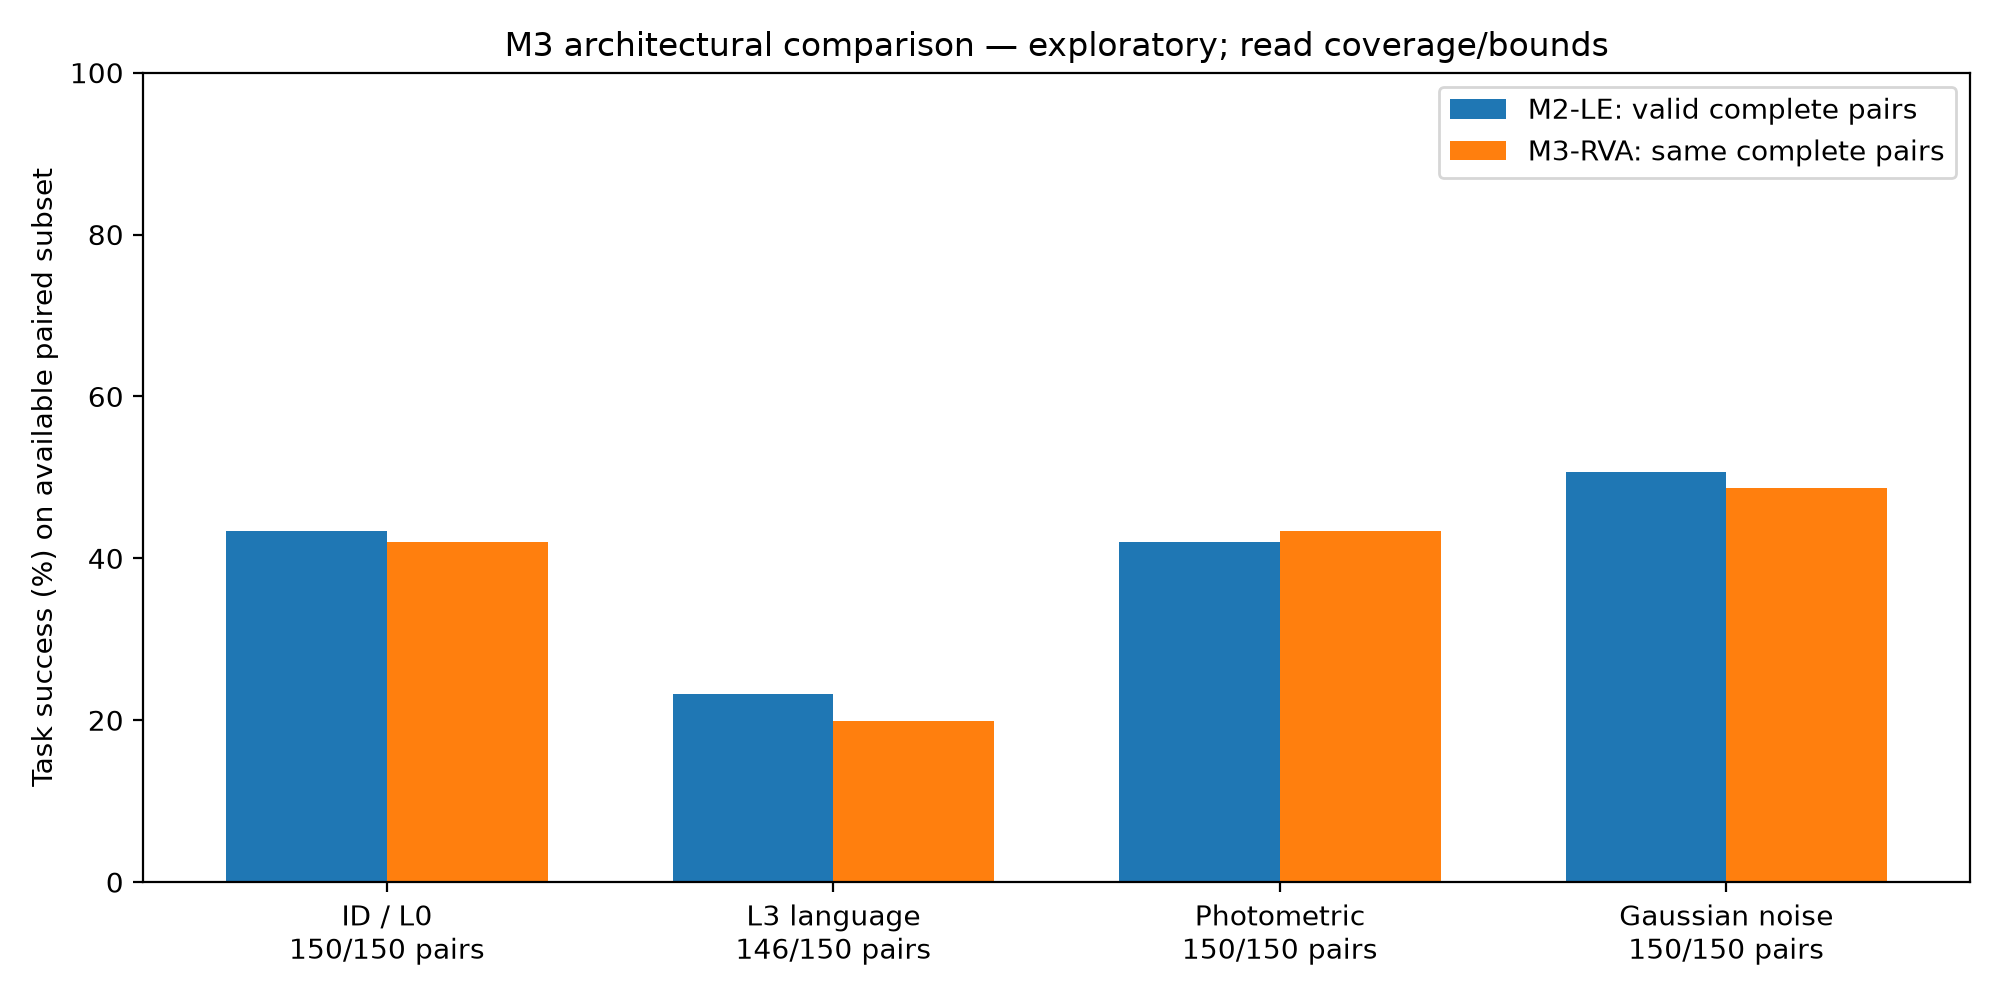

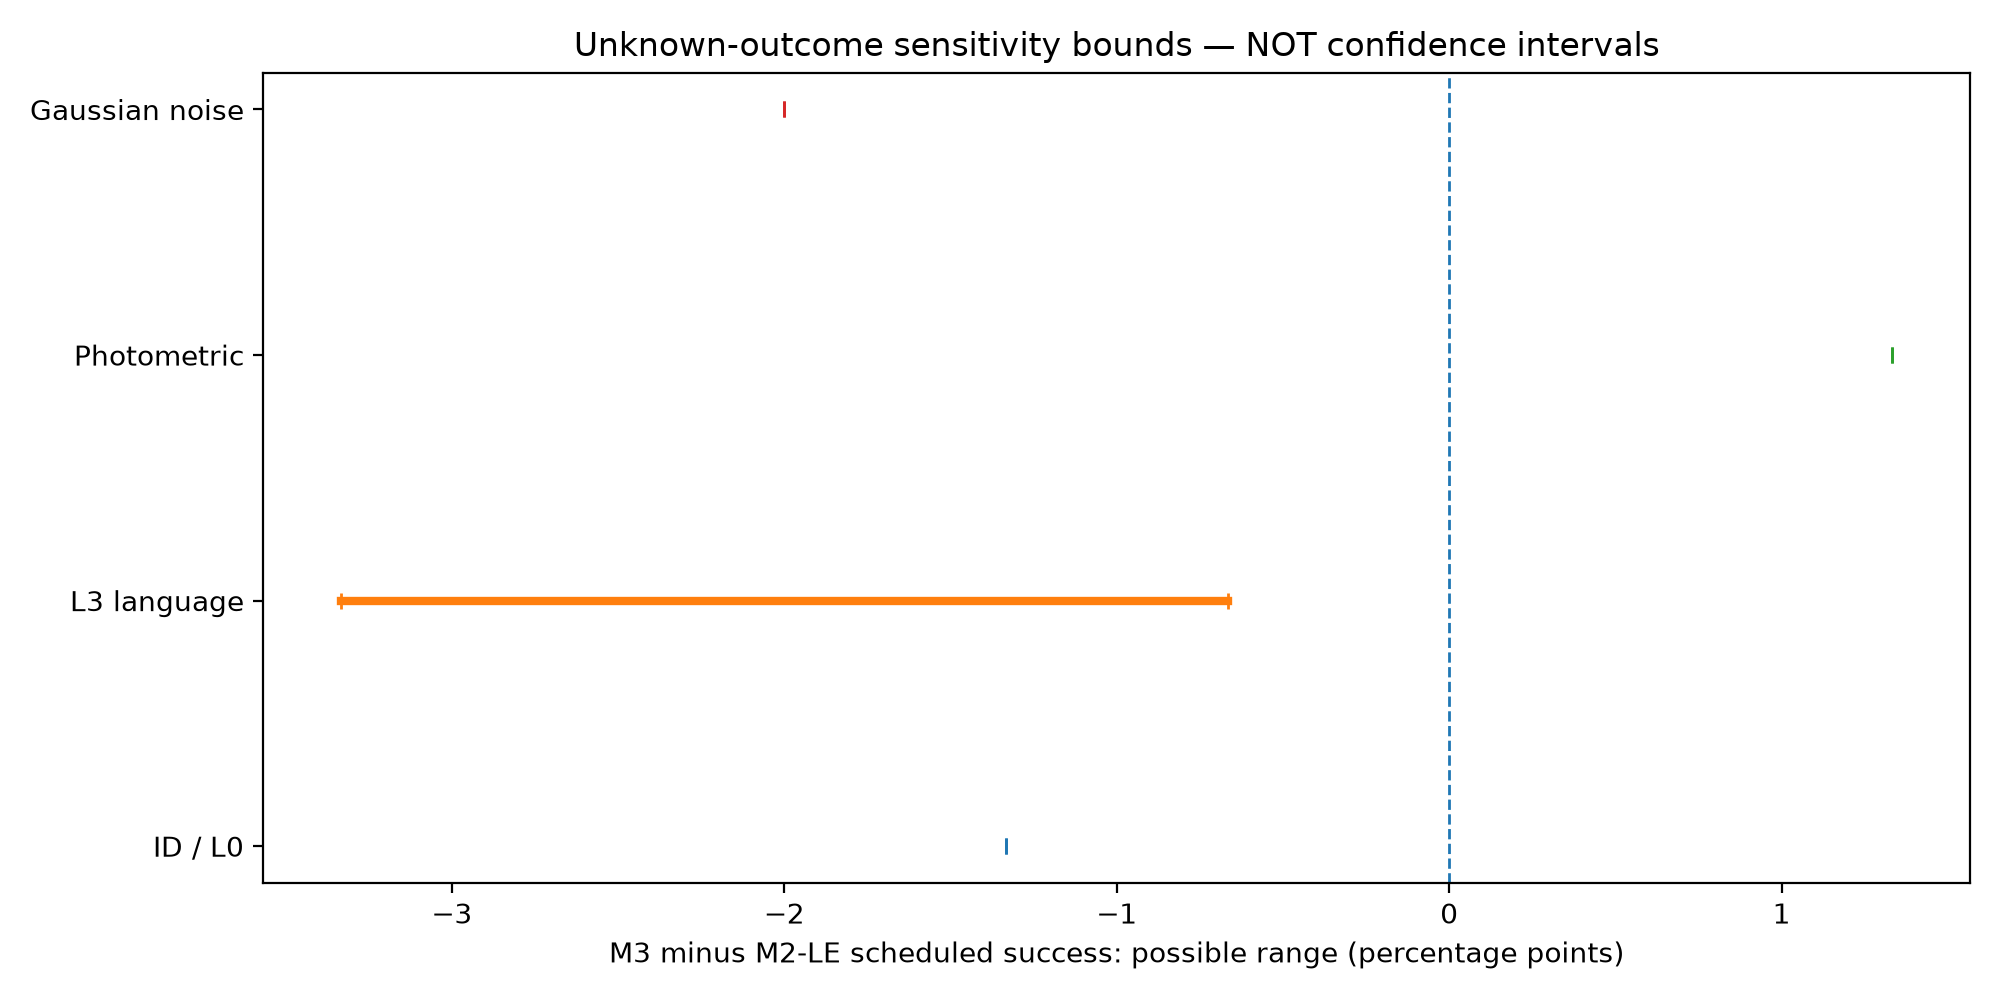


Summary for review: /home/leeming/projects/deep-learning-vla-robustness/results/metrics/m3_rva_evaluation/v2_completion_v1/notebook10_summary.json
Do not call the missing-pair condition a full success-rate experiment or claim M3 won from execution status.


In [7]:
summary_path = OUTPUT_DIR / "notebook10_summary.json"
if not summary_path.is_file():
    print("No completion summary yet. A successful plan cell is not a completed evaluation.")
else:
    summary = json.loads(summary_path.read_text(encoding="utf-8"))
    if summary.get("selected_seeds") != EVALUATION_SEEDS:
        raise RuntimeError("Saved summary belongs to another selected seed set; do not mislabel it.")
    for name in ("status", "execution_status", "planned_selected_episodes", "scored_episodes",
                 "valid_complete_pairs", "episodes_in_paired_analysis", "scored_but_unpaired_episodes",
                 "technical_unscored_attempts", "pending_slots", "valid_scored_matrix_complete",
                 "all_planned_seeds_evaluated", "preexisting_v2_files_preserved", "checkpoint_files_unchanged"):
        print(f"{name}: {summary.get(name)}")
    print("\nPaired estimates (only matching, valid complete pairs):")
    effects = pd.read_csv(OUTPUT_DIR / "m3_vs_m2le_effects.csv")
    display(effects[["condition_id", "complete_pairs", "planned_pairs", "pair_coverage_pct",
                     "M2_LE_success_pct", "M3_RVA_success_pct", "delta_pp", "inference_status"]])
    print("\nScheduled-outcome sensitivity bounds — not confidence intervals:")
    display(pd.read_csv(OUTPUT_DIR / "scheduled_matrix_bounds.csv"))
    if summary.get("technical_unscored_attempts", 0):
        terminal = pd.read_csv(OUTPUT_DIR / "unscored_attempts.csv")
        display(terminal[["model_seed", "variant", "condition_id", "suite_task_id", "replica", "status", "success"]])
    for name in ("m3_success_with_coverage.png", "m3_missing_outcome_bounds.png"):
        path = FIGURES_DIR / name
        if path.is_file():
            display(Image(filename=str(path)))
    print("\nSummary for review:", summary_path)
    print("Do not call the missing-pair condition a full success-rate experiment or claim M3 won from execution status.")


## 6. Report the limitation, then close the selected-seed extension

Suggested structure (replace bracketed values with actual saved evidence):

> The seed-[seed] architectural extension accounted for [N] scheduled model-episode slots.
> [n] complete model pairs satisfied the unchanged pairing rule and were used in the paired
> comparison. [u] attempts were unscored because image-only reset differences violated that rule;
> these were not manipulation failures and were not retried. Paired estimates therefore condition
> on the available valid subset. Coverage and worst-/best-case scheduled-outcome bounds are
> reported to expose the sensitivity to missing evidence. The renderer's determinism was not fixed
> by this completion amendment.

Do not report a successful synthetic test as a real GPU experiment. Do not claim an empty or partial
matrix is complete. Do not choose conditions, checkpoint seeds, or continuation criteria based on
which model wins. N00–N08 and the frozen N09 checkpoint remain separate and unmodified.

### Preparation validation
The companion and notebook were syntax-checked. The accompanying software tests cover the
unchanged rejection limits, actual task-8 captured arrays, state/schema/hash failures, persistence,
no-retry handling, valid-pair denominators, missing-outcome bounds, and a simulated resume from
367 scored entries. These are CPU software tests and stand-in outcomes, **not** an RTX 5090/LIBERO
execution or a claim that all possible runtime errors are eliminated.
